# station_grid_fusion 插件说明与示例

将站点观测融合到规则格点。本 notebook 使用：

- 站点：`resource/20260602000000.csv`（`obs_gust` / `fcst_wind`）
- 地形：`resource/HGT_M_1KM_CHINA.nc`（作底图与站点覆盖域参考）

| 插件 | 作用 |
| --- | --- |
| `InterpSgIdw` | 反距离权重；可选高斯衰减与背景偏差订正 |
| `InterpSgGaussian` | 最近邻 × 高斯半径扩散 |
| `InterpSgKriging` | 局部普通克里金 |
| `InterpSgCressman` | Cressman 逐步订正 |

接口均为 `process(sta, grid, background=None)`。详细参数见 `docs/station_grid_fusion.md`。

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
import pandas as pd

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_sg_cressman_plugin import InterpSgCressman
from interp_sg_gaussian_plugin import InterpSgGaussian
from interp_sg_idw_plugin import InterpSgIdw
from interp_sg_kriging import InterpSgKriging

print("PACKAGE_ROOT =", PACKAGE_ROOT)
print("DATA_DIR =", DATA_DIR)

d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


PACKAGE_ROOT = D:\workspace\test\00temp\station_grid_fusion
DATA_DIR = D:\workspace\test\00temp\station_grid_fusion\resource


## 1. 读入数据

- CSV 时间列需按文件名修正为 `2026-06-02`。
- 示例取 `dtime=24`，要素用 `obs_gust`；`fcst_wind` 先插到格点作偏差订正背景。
- 目标网格：覆盖站点范围的 0.1° 经纬网（便于演示）；地形底图用 HGT 子集。

In [2]:
def load_sta_obs_gust(path: Path, dtime: int = 24):
    sta = meb.read_stadata_from_csv(str(path))
    sta = sta.copy()
    sta["time"] = pd.to_datetime("2026-06-02")
    sta = meb.sele_by_para(sta, dtime=dtime)
    obs = sta[["level", "time", "dtime", "id", "lon", "lat", "obs_gust"]].copy()
    fcst = sta[["level", "time", "dtime", "id", "lon", "lat", "fcst_wind"]].copy()
    return obs, fcst


def spatial2d(da):
    return np.asarray(da.values, dtype=np.float64).reshape(
        -1, da.sizes["lat"], da.sizes["lon"]
    )[0]


obs, fcst = load_sta_obs_gust(DATA_DIR / "20260602000000.csv", dtime=24)
hgt = meb.read_griddata_from_nc(str(DATA_DIR / "HGT_M_1KM_CHINA.nc"))

lon0, lon1 = float(obs.lon.min()) - 0.5, float(obs.lon.max()) + 0.5
lat0, lat1 = float(obs.lat.min()) - 0.5, float(obs.lat.max()) + 0.5
tgt_grid = meb.basicdata.grid([lon0, lon1, 0.1], [lat0, lat1, 0.1])

# 地形底图：站点覆盖区，每隔 5 点抽样（约 0.05°）便于绘图
hgt_plot = hgt.sel(lon=slice(lon0, lon1), lat=slice(lat0, lat1)).isel(
    lon=slice(None, None, 5), lat=slice(None, None, 5)
)

print("obs stations:", len(obs), "lon/lat",
      round(lon0, 2), round(lon1, 2), round(lat0, 2), round(lat1, 2))
print("target grid:", tgt_grid.nlon, "x", tgt_grid.nlat)
print("hgt_plot:", dict(hgt_plot.sizes))

level,time,dtime,id,lon,lat,fcst_wind,obs_gust

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
obs stations: 334 lon/lat 99.6 120.48 31.54 38.49
target grid: 210 x 71
hgt_plot: {'member': 1, 'level': 1, 'time': 1, 'dtime': 1, 'lat': 140, 'lon': 418}


## 2. 输入场：地形 + 站点

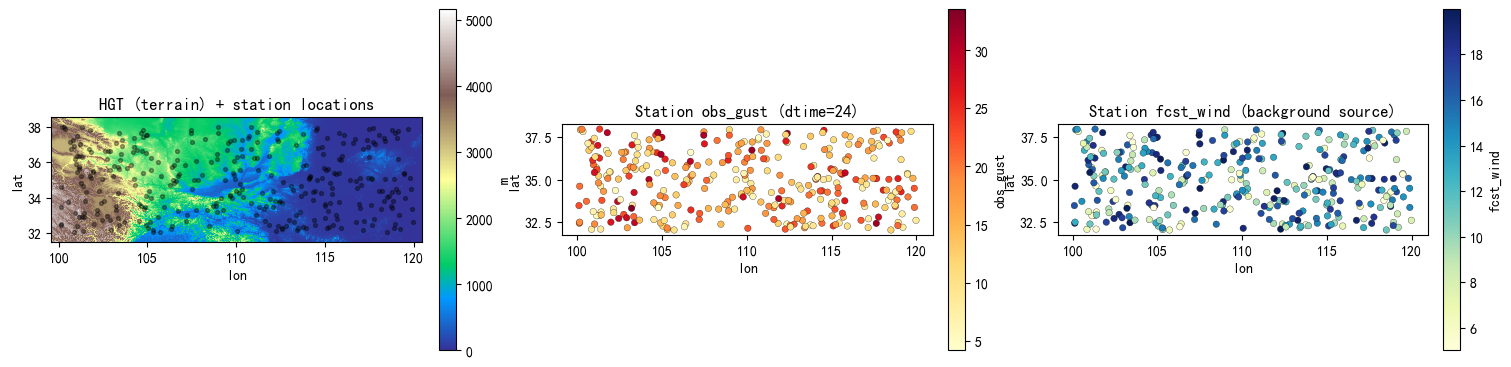

In [3]:
def plot_inputs(hgt_da, sta_obs, sta_fcst=None):
    hlons = np.asarray(hgt_da.lon.values)
    hlats = np.asarray(hgt_da.lat.values)
    hz = spatial2d(hgt_da)

    ncols = 2 if sta_fcst is None else 3
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4.2), constrained_layout=True)
    if ncols == 2:
        axes = list(axes)

    im0 = axes[0].pcolormesh(hlons, hlats, hz, shading="auto", cmap="terrain", rasterized=True)
    axes[0].scatter(sta_obs.lon, sta_obs.lat, s=8, c="k", alpha=0.35)
    axes[0].set_title("HGT (terrain) + station locations")
    axes[0].set_xlabel("lon"); axes[0].set_ylabel("lat"); axes[0].set_aspect("equal")
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="m")

    sc1 = axes[1].scatter(
        sta_obs.lon, sta_obs.lat, c=sta_obs.obs_gust, s=22, cmap="YlOrRd", edgecolors="k", linewidths=0.2
    )
    axes[1].set_title("Station obs_gust (dtime=24)")
    axes[1].set_xlabel("lon"); axes[1].set_ylabel("lat"); axes[1].set_aspect("equal")
    fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04, label="obs_gust")

    if sta_fcst is not None:
        sc2 = axes[2].scatter(
            sta_fcst.lon, sta_fcst.lat, c=sta_fcst.fcst_wind, s=22, cmap="YlGnBu",
            edgecolors="k", linewidths=0.2,
        )
        axes[2].set_title("Station fcst_wind (background source)")
        axes[2].set_xlabel("lon"); axes[2].set_ylabel("lat"); axes[2].set_aspect("equal")
        fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.04, label="fcst_wind")
    return fig


plot_inputs(hgt_plot, obs, fcst)
plt.show()

## 3. 调用示例（无背景）

| 插件 | 本示例参数要点 |
| --- | --- |
| IDW | `effectR=150000`（米）、`nearNum=8` |
| IDW×高斯 | `gaussian=True`，`effectR` 作高斯半径 |
| Gaussian | `halfR=80000` |
| Kriging | `model="spherical"`, `nearNum=12` |
| Cressman | `r_list` 由大到小多扫 |

In [4]:
results = {}
results["IDW"] = InterpSgIdw(effectR=150000, nearNum=8, decrease=2).process(obs, tgt_grid)
results["IDW x Gaussian"] = InterpSgIdw(
    effectR=80000, nearNum=8, decrease=2, gaussian=True
).process(obs, tgt_grid)
results["Gaussian"] = InterpSgGaussian(halfR=80000).process(obs, tgt_grid)
results["Kriging"] = InterpSgKriging(model="spherical", nearNum=12).process(obs, tgt_grid)
results["Cressman"] = InterpSgCressman(
    r_list=[200000, 100000, 50000], nearNum=40
).process(obs, tgt_grid)

for k, da in results.items():
    z = spatial2d(da)
    print(f"{k:16s} shape={z.shape} min={np.nanmin(z):.2f} max={np.nanmax(z):.2f}")

IDW              shape=(71, 210) min=4.64 max=33.10
IDW x Gaussian   shape=(71, 210) min=4.64 max=33.10
Gaussian         shape=(71, 210) min=4.23 max=33.52
Kriging          shape=(71, 210) min=5.12 max=33.46
Cressman         shape=(71, 210) min=10.73 max=23.93


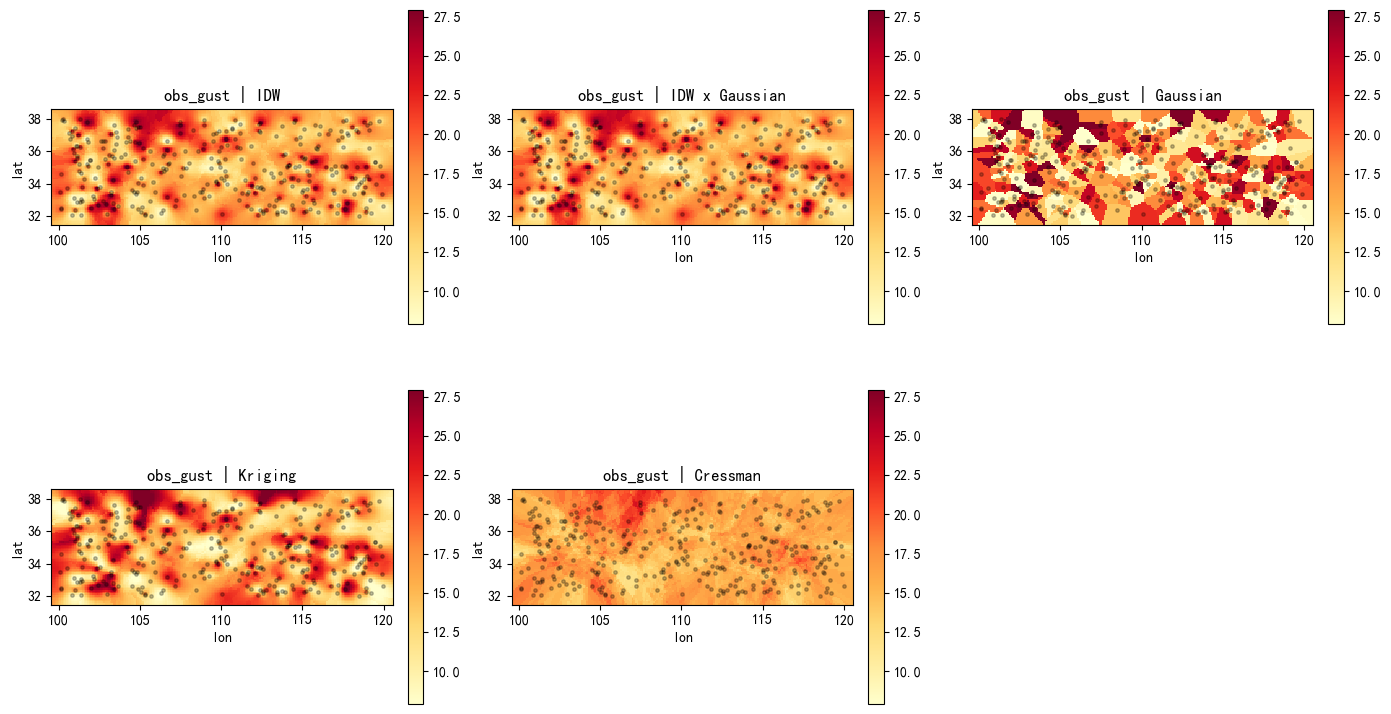

In [5]:
def plot_results(res_dict, sta_obs, title_prefix=""):
    keys = list(res_dict.keys())
    n = len(keys)
    ncols = 3
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.8 * nrows), constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()

    # 共用色标范围
    vals = np.concatenate([spatial2d(res_dict[k]).ravel() for k in keys])
    vals = vals[np.isfinite(vals)]
    vmin, vmax = np.percentile(vals, [2, 98])

    for i, key in enumerate(keys):
        da = res_dict[key]
        lon = np.asarray(da.lon.values)
        lat = np.asarray(da.lat.values)
        z = spatial2d(da)
        im = axes[i].pcolormesh(
            lon, lat, z, shading="auto", cmap="YlOrRd", vmin=vmin, vmax=vmax, rasterized=True
        )
        axes[i].scatter(sta_obs.lon, sta_obs.lat, s=6, c="k", alpha=0.25)
        axes[i].set_title(f"{title_prefix}{key}")
        axes[i].set_xlabel("lon"); axes[i].set_ylabel("lat"); axes[i].set_aspect("equal")
        fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    return fig


plot_results(results, obs, title_prefix="obs_gust | ")
plt.show()

## 4. 带背景场的偏差订正示例

四个插件都支持 `background`（格点场）。本例无现成格点背景，故先将站点 `fcst_wind` 用 IDW 插到目标网格作为**演示用**背景，再对 `obs_gust` 分别调用：

- IDW / IDW×高斯 / Gaussian / Kriging：偏差订正（插 `obs − bg` 再叠回）
- Cressman：以背景为初估场做逐步订正

background (fcst IDW)    min=5.20 max=19.94
IDW + bg                 min=3.06 max=33.53
IDW x Gauss + bg         min=3.06 max=33.53
Gaussian + bg            min=2.91 max=35.63
Kriging + bg             min=3.21 max=33.73
Cressman + bg            min=7.47 max=25.16


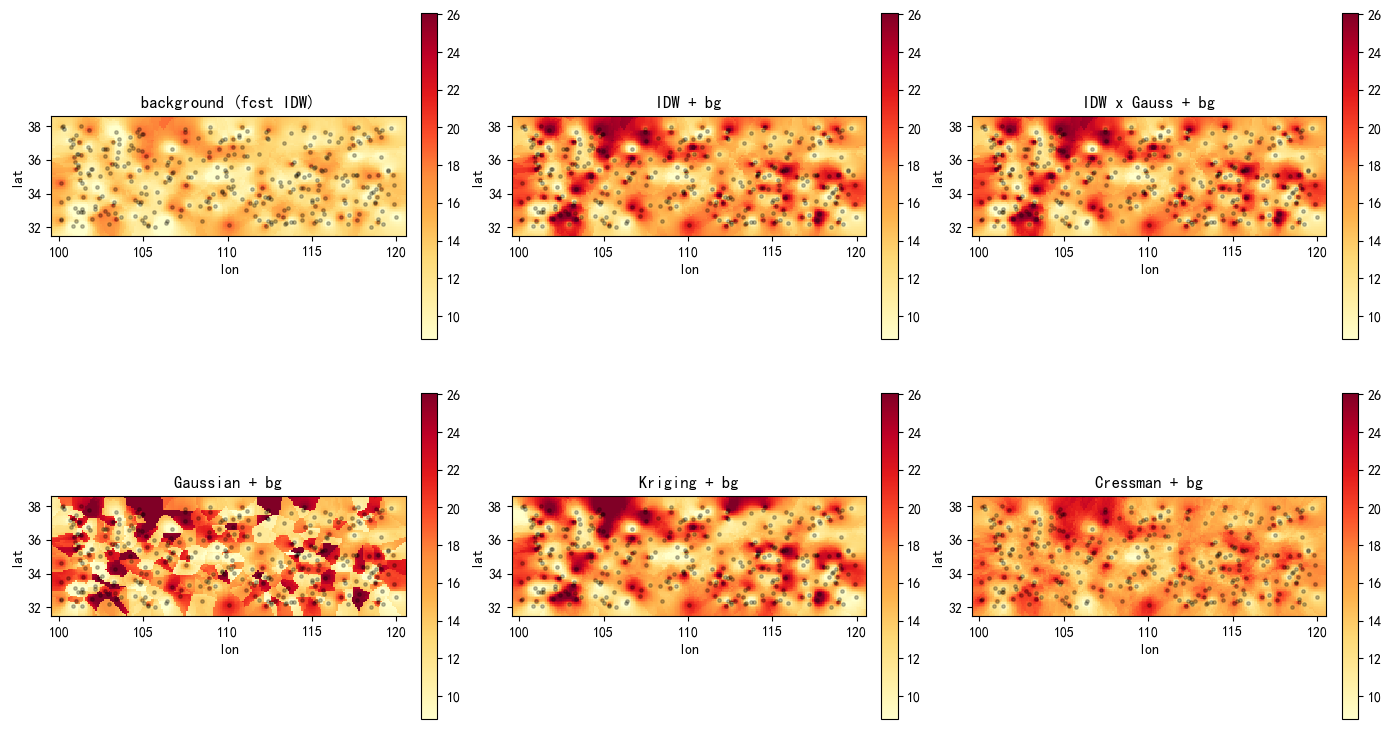

In [6]:
bg = InterpSgIdw(effectR=150000, nearNum=8, decrease=2).process(fcst, tgt_grid)

with_bg = {}
with_bg["background (fcst IDW)"] = bg
with_bg["IDW + bg"] = InterpSgIdw(
    effectR=150000, nearNum=8, decrease=2, outer_value=0.0
).process(obs, tgt_grid, background=bg)
with_bg["IDW x Gauss + bg"] = InterpSgIdw(
    effectR=80000, nearNum=8, decrease=2, gaussian=True, outer_value=0.0
).process(obs, tgt_grid, background=bg)
with_bg["Gaussian + bg"] = InterpSgGaussian(
    halfR=80000, outer_value=0.0
).process(obs, tgt_grid, background=bg)
with_bg["Kriging + bg"] = InterpSgKriging(
    model="spherical", nearNum=12, outer_value=0.0
).process(obs, tgt_grid, background=bg)
with_bg["Cressman + bg"] = InterpSgCressman(
    r_list=[200000, 100000, 50000], nearNum=40, outer_value=0.0
).process(obs, tgt_grid, background=bg)

for k, da in with_bg.items():
    z = spatial2d(da)
    print(f"{k:24s} min={np.nanmin(z):.2f} max={np.nanmax(z):.2f}")

plot_results(with_bg, obs)
plt.show()

## 5. 小结

- 输入：站点 CSV + HGT 地形（底图）；分析要素为 `obs_gust`。  
- 无背景：五种（含 IDW 高斯）插值结果对比。  
- 有背景：四个插件均可传 `background`；本例用 `fcst_wind` IDW 作演示背景，正式请用格点预报。IDW / Gaussian / Kriging 为偏差订正，Cressman 为初估场逐步订正。  
- CLI：`python -m cli --module idw|gaussian|kriging|cressman ...`（见 `docs/station_grid_fusion.md`）。